# Supplementary Figures


In [1]:
from pathlib import Path
import json
import sys

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc

from matplotlib.colors import PowerNorm
from matplotlib.lines import Line2D
from sklearn.metrics import confusion_matrix


# ============================================================
# Repository + shared paths
# ============================================================

def find_repo_root(start=Path.cwd()):
    start = Path(start).resolve()
    for p in [start, *start.parents]:
        if (p / "src" / "scrna_benchmark").is_dir():
            return p
    raise RuntimeError(
        "Run this notebook from somewhere inside the repository."
    )


REPO_ROOT = find_repo_root()

if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

CACHE_DIR = REPO_ROOT / "results/figure_data"
FIG_DIR = REPO_ROOT / "figures/supplementary"

# Figure exports use PNG and TIFF at 350 DPI.
# Existing UMAP caches are read unchanged.
# CACHE_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# Dataset metadata
# ============================================================

DATASETS = {
    "PBMC": {
        "key": "pbmc",
        "adata": (
            REPO_ROOT
            / "data/PBMC_Stephenson/stephenson_benchmark_ready.h5ad"
        ),
        "results": REPO_ROOT / "results/pbmc_no_batch",
        "donor_col": "patient_id",
        "celltype_col": "cell_type",
        "technical_candidates": ["Site"],
        "technical_label": "Site",
    },
    "Lung": {
        "key": "lung",
        "adata": REPO_ROOT / "data/lung/lung_benchmark_ready.h5ad",
        "results": REPO_ROOT / "results/lung_no_batch_L4",
        "donor_col": "donor_id",
        "celltype_col": "cell_type",
        "technical_candidates": ["batch", "dataset"],
        "technical_label": "Source dataset",
    },
    "Kidney": {
        "key": "kidney",
        "adata": REPO_ROOT / "data/kidney/kidney_benchmark_ready.h5ad",
        "results": REPO_ROOT / "results/kidney_no_batch",
        "donor_col": "donor_id",
        "celltype_col": "cell_type",
        "technical_candidates": ["batch", "library_preparation_batch"],
        "technical_label": "Library-preparation batch",
    },
    "Pancreas": {
        "key": "pancreas",
        "adata": REPO_ROOT / "data/pancreas/pancreas_benchmark_ready.h5ad",
        "results": REPO_ROOT / "results/pancreas_no_batch",
        "donor_col": "donor_id",
        "celltype_col": "cell_type",
        "technical_candidates": ["batch", "Center"],
        "technical_label": "Center / batch",
    },
    "Blood Atlas": {
        "key": "blood_atlas",
        "adata": (
            REPO_ROOT
            / "data/blood_atlas/blood_atlas_benchmark_ready.h5ad"
        ),
        "results": REPO_ROOT / "results/blood_atlas_no_batch",
        "donor_col": "donor_id",
        "celltype_col": "cell_type",
        "technical_candidates": ["batch"],
        "technical_label": "Acquisition batch",
    },
}

REP_ORDER = ["hvg", "pca", "harmony", "scvi"]

REP_LABELS = {
    "hvg": "HVG",
    "pca": "PCA",
    "harmony": "Harmony",
    "scvi": "scVI",
}

BLUE = "#1f77b4"
ORANGE = "#ff7f0e"
GRAY = "#666666"


# ============================================================
# Shared styling
# ============================================================

plt.rcParams.update({
    "font.size": 12,
    "axes.titlesize": 13,
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 10.5,
})


def clean_axis(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


def panel_letter(ax, letter, x=-0.08, y=1.02):
    ax.text(
        x,
        y,
        letter,
        transform=ax.transAxes,
        fontsize=15,
        fontweight="bold",
        va="bottom",
        ha="left",
        clip_on=False,
    )


# ============================================================
# Shared export helper: PNG + TIFF at 350 DPI
# ============================================================

def export_figure(fig, stem):
    """Save PNG and LZW-compressed TIFF at 350 DPI."""
    FIG_DIR.mkdir(parents=True, exist_ok=True)

    save_options = {
        "dpi": 350,
        "bbox_inches": "tight",
        "facecolor": "white",
    }

    fig.savefig(
        FIG_DIR / f"{stem}.png",
        **save_options,
    )

    fig.savefig(
        FIG_DIR / f"{stem}.tif",
        **save_options,
        pil_kwargs={"compression": "tiff_lzw"},
    )


# ============================================================
# UMAP helper
# ============================================================

def get_or_make_umap(dataset_name, requested_cols):
    """
    Reuse the manuscript-figure PCA UMAP cache when available.
    If a requested metadata column is absent from the cache, join it
    from the frozen benchmark-ready AnnData object.
    """
    info = DATASETS[dataset_name]
    cache = CACHE_DIR / f"{info['key']}_umap_pca.csv"

    if cache.exists():
        coords = pd.read_csv(cache, index_col=0)
        coords.index = coords.index.astype(str)
    else:
        adata = ad.read_h5ad(info["adata"])
        sc.pp.neighbors(adata, use_rep="X_pca", random_state=42)
        sc.tl.umap(adata, random_state=42)

        coords = pd.DataFrame(
            adata.obsm["X_umap"],
            index=adata.obs_names.astype(str),
            columns=["UMAP1", "UMAP2"],
        )

        for col in requested_cols:
            if col in adata.obs.columns:
                coords[col] = adata.obs[col].astype(str).to_numpy()

        # Uncomment only if writing caches.
        # cache.parent.mkdir(parents=True, exist_ok=True)
        # coords.to_csv(cache)
        return coords

    missing_cols = [
        c for c in requested_cols
        if c not in coords.columns
    ]

    if missing_cols:
        adata = ad.read_h5ad(info["adata"], backed="r")
        existing = [
            c for c in missing_cols
            if c in adata.obs.columns
        ]

        if existing:
            meta = adata.obs[existing].astype(str).copy()
            meta.index = meta.index.astype(str)
            coords = coords.join(meta, how="left")

        if hasattr(adata, "file") and adata.file is not None:
            adata.file.close()

    return coords


def choose_existing_column(adata_path, candidates):
    adata = ad.read_h5ad(adata_path, backed="r")

    chosen = next(
        (c for c in candidates if c in adata.obs.columns),
        None,
    )

    if hasattr(adata, "file") and adata.file is not None:
        adata.file.close()

    return chosen


# ============================================================
# Per-class F1 + confusion helpers
# ============================================================

def load_per_class_matrix(donor_cv_dir):
    donor_cv_dir = Path(donor_cv_dir)
    parts = []

    for rep in REP_ORDER:
        path = donor_cv_dir / f"donor_cv_{rep}_mean_per_class_f1.csv"

        if not path.exists():
            continue

        df = pd.read_csv(path)
        parts.append(
            df.set_index("cell_type")["f1"].rename(rep)
        )

    if not parts:
        raise FileNotFoundError(
            f"No per-class F1 tables found in {donor_cv_dir}"
        )

    matrix = pd.concat(parts, axis=1)
    matrix["_mean"] = matrix.mean(axis=1)

    matrix = (
        matrix
        .sort_values("_mean", ascending=False)
        .drop(columns="_mean")
    )

    return matrix


def normalized_confusion(pred_path):
    pred = pd.read_csv(pred_path)

    labels = sorted(
        set(pred["y_true"].astype(str))
        | set(pred["y_pred"].astype(str))
    )

    cm = confusion_matrix(
        pred["y_true"].astype(str),
        pred["y_pred"].astype(str),
        labels=labels,
    )

    row_sums = cm.sum(axis=1, keepdims=True)

    cm_norm = np.divide(
        cm.astype(float),
        row_sums,
        out=np.zeros_like(cm, dtype=float),
        where=row_sums != 0,
    )

    return cm_norm, labels


def summarize_random_metrics(path):
    df = pd.read_csv(path)

    return (
        df.groupby("representation", as_index=False)
        .agg(
            macro_f1_mean=("macro_f1", "mean"),
            macro_f1_std=("macro_f1", "std"),
            accuracy_mean=("accuracy", "mean"),
            accuracy_std=("accuracy", "std"),
        )
    )


print("Repository:", REPO_ROOT)

Repository: /users/xchen5/scRNA-cross-donor-generalization


## Figure S1 — Benchmark population and cell-type support


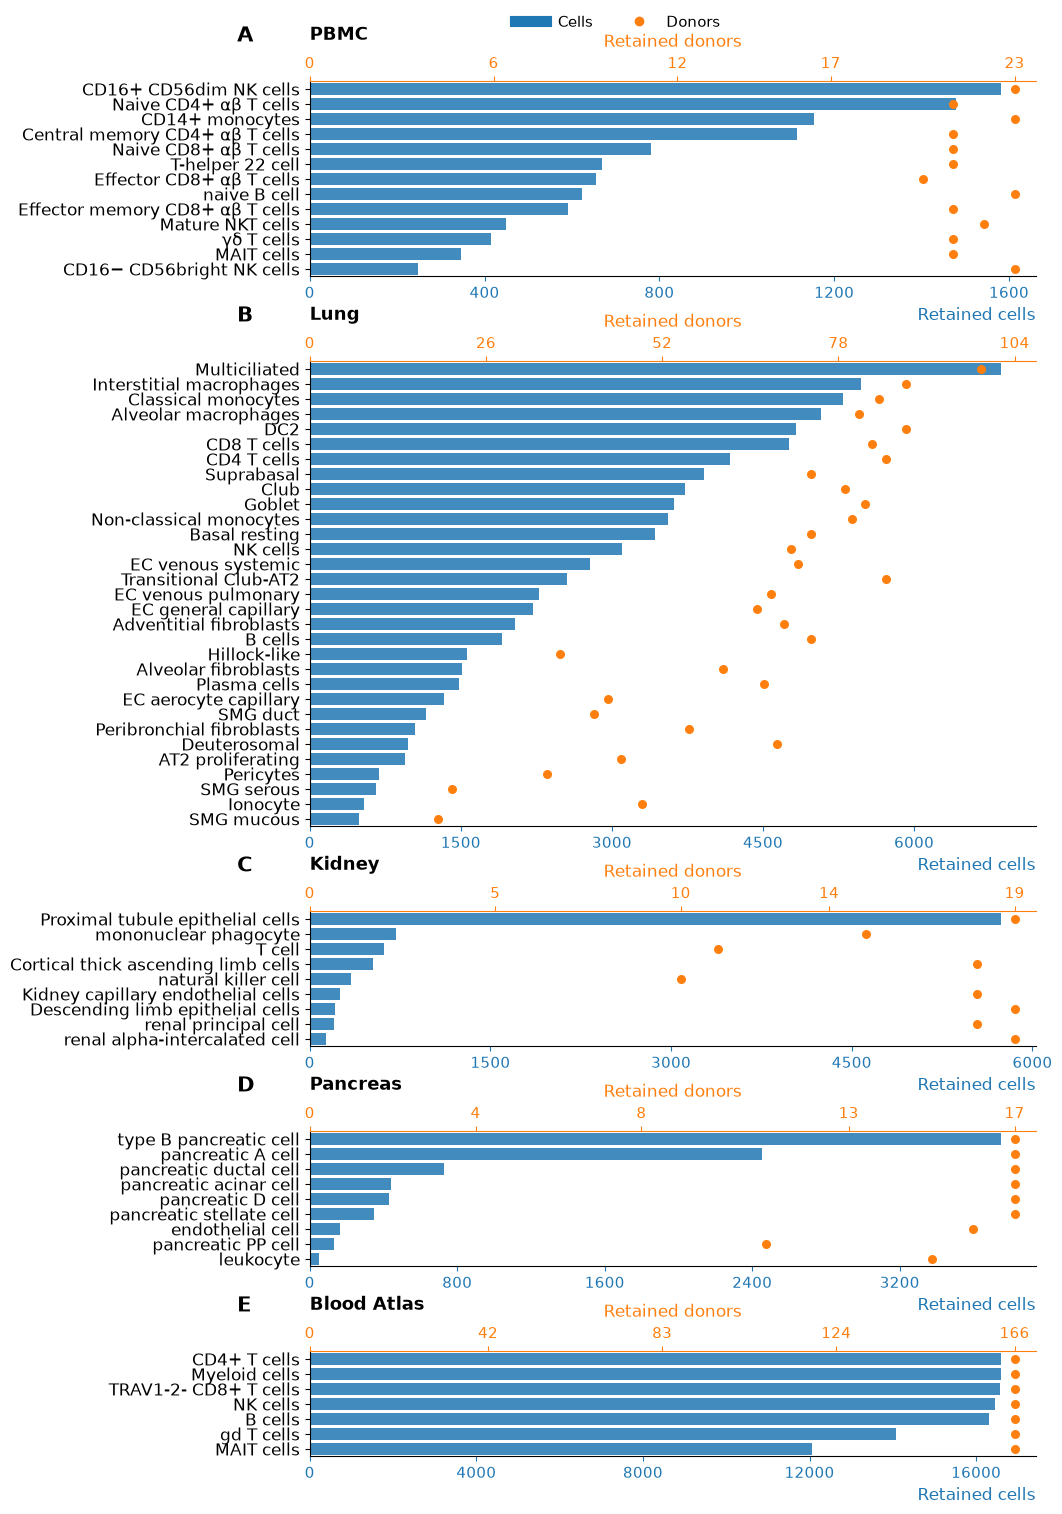

In [2]:
# ============================================================
# Figure S1 — Benchmark population and cell-type support
# ============================================================

from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator


# Short display labels only; underlying annotations are unchanged.
CELLTYPE_DISPLAY = {
    "CD14-positive monocyte": "CD14+ monocytes",
    "CD16-positive, CD56-dim natural killer cell, human":
        "CD16+ CD56dim NK cells",
    "CD16-negative, CD56-bright natural killer cell, human":
        "CD16− CD56bright NK cells",
    "naive thymus-derived CD4-positive, alpha-beta T cell":
        "Naive CD4+ αβ T cells",
    "naive thymus-derived CD8-positive, alpha-beta T cell":
        "Naive CD8+ αβ T cells",
    "central memory CD4-positive, alpha-beta T cell":
        "Central memory CD4+ αβ T cells",
    "effector CD8-positive, alpha-beta T cell":
        "Effector CD8+ αβ T cells",
    "effector memory CD8-positive, alpha-beta T cell":
        "Effector memory CD8+ αβ T cells",
    "gamma-delta T cell": "γδ T cells",
    "mature NK T cell": "Mature NKT cells",
    "mucosal invariant T cell": "MAIT cells",
    "epithelial cell of proximal tubule":
        "Proximal tubule epithelial cells",
    "kidney loop of Henle cortical thick ascending limb epithelial cell":
        "Cortical thick ascending limb cells",
    "kidney loop of Henle descending limb epithelial cell":
        "Descending limb epithelial cells",
    "kidney capillary endothelial cell":
        "Kidney capillary endothelial cells",
}


# ============================================================
# Load cell-type support and total donor counts
# ============================================================

support_tables = {}
cohort_donor_counts = {}

for dataset, info in DATASETS.items():
    adata = ad.read_h5ad(info["adata"], backed="r")

    try:
        obs = pd.DataFrame({
            "cell_type": adata.obs[info["celltype_col"]].astype(str),
            "donor": adata.obs[info["donor_col"]].astype(str),
        })

        cohort_donor_counts[dataset] = obs["donor"].nunique()

        support_tables[dataset] = (
            obs.groupby("cell_type", observed=True)
            .agg(
                n_cells=("cell_type", "size"),
                n_donors=("donor", "nunique"),
            )
            .sort_values("n_cells", ascending=False)
        )

    finally:
        if hasattr(adata, "file") and adata.file is not None:
            adata.file.close()


# ============================================================
# Layout: five stacked panels with consistent row spacing
# ============================================================

# Height in inches allocated to each panel.
panel_heights = {
    dataset: 0.15 * len(support_tables[dataset])
    for dataset in DATASETS
}

panel_gap = 0.85
top_margin = 0.80
bottom_margin = 0.55

figure_height = (
    sum(panel_heights.values())
    + panel_gap * (len(DATASETS) - 1)
    + top_margin
    + bottom_margin
)

fig = plt.figure(figsize=(11, figure_height))

panel_letters = list("ABCDE")
panel_top = figure_height - top_margin


# ============================================================
# Draw panels
# ============================================================

for row, dataset in enumerate(DATASETS):
    support = support_tables[dataset]
    y = np.arange(len(support))

    panel_height = panel_heights[dataset]
    panel_bottom = panel_top - panel_height

    # Explicit positions preserve row spacing with the paired x axes.
    ax = fig.add_axes([
        0.32,
        panel_bottom / figure_height,
        0.66,
        panel_height / figure_height,
    ])

    # --------------------
    # Retained cells: bottom axis
    # --------------------
    ax.barh(
        y,
        support["n_cells"],
        color=BLUE,
        alpha=0.85,
        height=0.75,
    )

    ax.set_yticks(y)
    ax.set_yticklabels(
        [
            CELLTYPE_DISPLAY.get(label, label)
            for label in support.index
        ],
        fontsize=12,
    )

    # Descending cell counts from top to bottom.
    ax.set_ylim(len(support) - 0.5, -0.5)

    ax.set_xlabel(
        "Retained cells",
        color=BLUE,
        fontsize=12,
        loc="right",
    )

    ax.tick_params(
        axis="x",
        colors=BLUE,
        labelsize=11,
    )

    ax.xaxis.set_major_locator(
        MaxNLocator(nbins=5, integer=True)
    )

    ax.set_xlim(
        0,
        support["n_cells"].max() * 1.05,
    )

    ax.set_title(
        dataset,
        loc="left",
        fontweight="bold",
        fontsize=13,
        y=1.0,
        pad=30,
    )

    clean_axis(ax)

    # --------------------
    # Retained donors: top axis
    # --------------------
    ax2 = ax.twiny()

    ax2.scatter(
        support["n_donors"],
        y,
        color=ORANGE,
        s=30,
        zorder=3,
    )

    total_donors = int(cohort_donor_counts[dataset])

    # Include zero and leave room for points at the cohort total.
    ax2.set_xlim(
        0,
        total_donors * 1.03,
    )

    # Integer ticks, including the actual cohort donor count.
    donor_ticks = np.unique(
        np.round(
            np.linspace(0, total_donors, 5)
        ).astype(int)
    )

    ax2.set_xticks(donor_ticks)

    ax2.set_xlabel(
        "Retained donors",
        color=ORANGE,
        fontsize=12,
        labelpad=7,
    )

    ax2.tick_params(
        axis="x",
        colors=ORANGE,
        labelsize=11,
    )

    ax2.spines["top"].set_color(ORANGE)
    ax2.spines["bottom"].set_visible(False)
    ax2.spines["right"].set_visible(False)
    ax2.spines["left"].set_visible(False)

    # --------------------
    # Panel letter
    # --------------------
    panel_letter(
        ax,
        panel_letters[row],
        x=-0.10,
        y=1 + 0.35 / panel_height,
    )

    panel_top = panel_bottom - panel_gap


# ============================================================
# Figure-level legend
# ============================================================

legend_handles = [
    Line2D(
        [0], [0],
        color=BLUE,
        linewidth=8,
        label="Cells",
    ),
    Line2D(
        [0], [0],
        marker="o",
        linestyle="None",
        color=ORANGE,
        markersize=6,
        label="Donors",
    ),
]

fig.legend(
    handles=legend_handles,
    frameon=False,
    loc="upper center",
    bbox_to_anchor=(0.60, 1.0),
    ncol=2,
    fontsize=11,
)


# ============================================================
# Export: PNG + LZW TIFF, both at 350 DPI
# ============================================================

export_figure(
    fig,
    "figure_S1_population_support",
)

plt.show()

## Figure S2 — Cell-type UMAPs


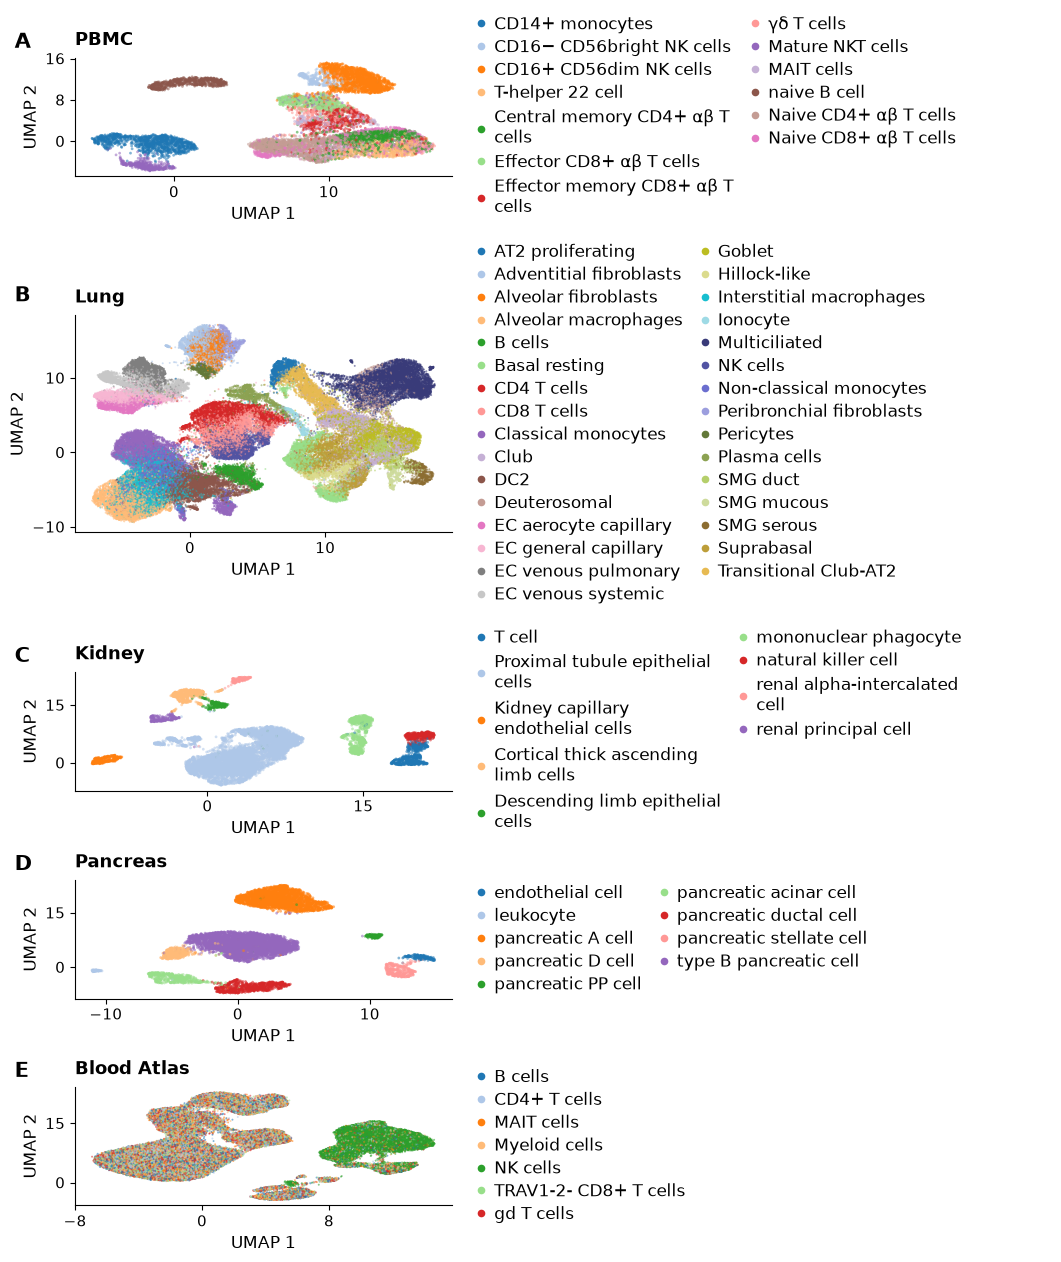

In [3]:
# ============================================================
# Figure S2 — Cell-type UMAPs
# ============================================================

from textwrap import fill
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator


# Reuse the display-name mapping defined in the revised S1 cell.
display_labels = CELLTYPE_DISPLAY

# Enough distinct palette entries for Lung's 31 cell types.
palette = [
    color
    for name in ("tab20", "tab20b", "tab20c")
    for color in plt.get_cmap(name).colors
]


# ============================================================
# Load existing UMAP coordinates and annotations
# ============================================================

panel_data = []

for dataset, info in DATASETS.items():
    col = info["celltype_col"]

    coords = get_or_make_umap(
        dataset,
        [col],
    )

    labels = (
        coords[col]
        .astype("string")
        .fillna("Unannotated")
        .astype(str)
    )

    categories = sorted(labels.unique())

    if len(categories) > len(palette):
        raise ValueError(
            f"{dataset}: more categories than available colors."
        )

    panel_data.append(
        (dataset, coords, labels, categories)
    )


# ============================================================
# Layout: stacked UMAPs with a separate legend column
# ============================================================

height_ratios = []

for _, _, _, categories in panel_data:
    legend_columns = 2 if len(categories) > 8 else 1
    legend_rows = int(
        np.ceil(len(categories) / legend_columns)
    )

    # Give Lung extra room for its longer legend.
    height_ratios.append(
        max(1.4, 0.16 * legend_rows)
    )

fig = plt.figure(
    figsize=(10.5, 12.5),
    layout="constrained",
)

gs = fig.add_gridspec(
    len(panel_data),
    2,
    width_ratios=[1, 1.55],
    height_ratios=height_ratios,
    wspace=0.03,
    hspace=0.06,
)

panel_letters = list("ABCDE")


# ============================================================
# Draw panels
# ============================================================

for i, (dataset, coords, labels, categories) in enumerate(panel_data):
    ax = fig.add_subplot(gs[i, 0])

    legend_ax = fig.add_subplot(gs[i, 1])
    legend_ax.axis("off")

    color_map = dict(
        zip(categories, palette)
    )

    # Deterministically interleave categories to reduce drawing-order bias.
    # The UMAP coordinates themselves remain unchanged.
    order = np.random.default_rng(42).permutation(
        len(coords)
    )

    ax.scatter(
        coords["UMAP1"].to_numpy()[order],
        coords["UMAP2"].to_numpy()[order],
        c=[
            color_map[label]
            for label in labels.to_numpy()[order]
        ],
        s=2 if len(coords) > 50000 else 4,
        alpha=0.55,
        linewidths=0,
        rasterized=True,
    )

    ax.set_xlabel(
        "UMAP 1",
        fontsize=12,
    )

    ax.set_ylabel(
        "UMAP 2",
        fontsize=12,
    )

    ax.tick_params(
        labelsize=10.5,
    )

    ax.xaxis.set_major_locator(
        MaxNLocator(nbins=3)
    )

    ax.yaxis.set_major_locator(
        MaxNLocator(nbins=3)
    )

    ax.set_title(
        dataset,
        loc="left",
        fontweight="bold",
        fontsize=13,
        pad=9,
    )

    clean_axis(ax)

    panel_letter(
        ax,
        panel_letters[i],
        x=-0.16,
        y=1.04,
    )

    # --------------------
    # Readable legend
    # --------------------
    handles = [
        Line2D(
            [],
            [],
            marker="o",
            linestyle="None",
            markerfacecolor=color_map[label],
            markeredgecolor="none",
            markersize=5.5,
            label=fill(
                display_labels.get(label, label),
                width=27,
                break_long_words=False,
                break_on_hyphens=False,
            ),
        )
        for label in categories
    ]

    legend_ax.legend(
        handles=handles,
        frameon=False,
        loc="center left",
        fontsize=12,
        ncol=2 if len(categories) > 8 else 1,
        handlelength=0.8,
        handletextpad=0.4,
        columnspacing=0.9,
        labelspacing=0.35,
        borderaxespad=0,
    )


# ============================================================
# Export: PNG + LZW TIFF, both at 350 DPI
# ============================================================

export_figure(
    fig,
    "figure_S2_celltype_umaps",
)

plt.show()

## Figure S3 — Technical/source UMAPs


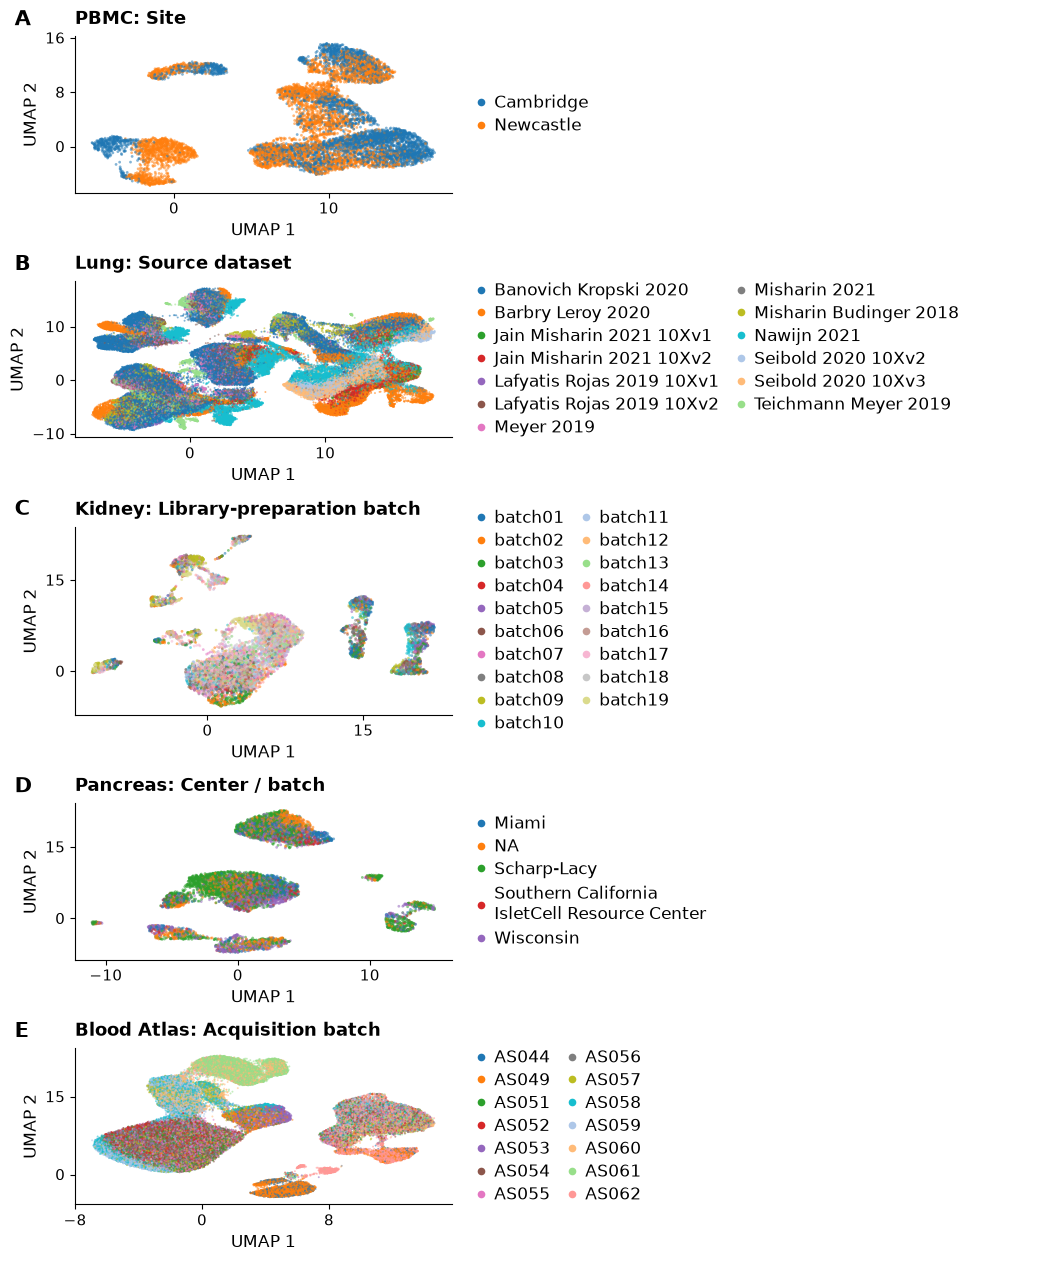

In [4]:
# ============================================================
# Figure S3 — Technical/source UMAPs
# ============================================================

from textwrap import fill
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator


# Distinct hues first, then lighter shades for larger category sets.
# PBMC's two sites therefore use blue and orange.
tab20_colors = list(plt.get_cmap("tab20").colors)

palette = (
    tab20_colors[::2]
    + tab20_colors[1::2]
    + list(plt.get_cmap("tab20b").colors)
    + list(plt.get_cmap("tab20c").colors)
)


# ============================================================
# Load existing UMAP coordinates and technical annotations
# ============================================================

panel_data = []
height_ratios = []

for dataset, info in DATASETS.items():
    technical_col = choose_existing_column(
        info["adata"],
        info["technical_candidates"],
    )

    if technical_col is None:
        raise ValueError(
            f"{dataset}: no technical/source column found."
        )

    coords = get_or_make_umap(
        dataset,
        [technical_col],
    )

    if technical_col not in coords.columns:
        raise KeyError(
            f"{dataset}: {technical_col!r} missing from UMAP metadata."
        )

    labels = (
        coords[technical_col]
        .astype("string")
        .fillna("Missing")
        .astype(str)
        .replace({
            "nan": "Missing",
            "None": "Missing",
            "<NA>": "Missing",
        })
    )

    categories = sorted(labels.unique())

    if len(categories) > len(palette):
        raise ValueError(
            f"{dataset}: more categories than available colors."
        )

    # Display edits only: original identifiers still define the groups.
    legend_labels = {}

    for label in categories:
        name = (
            "Newcastle"
            if dataset == "PBMC" and label == "Ncl"
            else label
        )

        legend_labels[label] = fill(
            name.replace("_", " "),
            width=27,
            break_long_words=False,
            break_on_hyphens=False,
        )

    # Account for wrapped labels when allocating panel heights.
    legend_columns = 2 if len(categories) > 8 else 1

    groups = np.array_split(
        np.arange(len(categories)),
        legend_columns,
    )

    max_lines = max(
        sum(
            legend_labels[categories[j]].count("\n") + 1
            for j in group
        )
        for group in groups
    )

    height_ratios.append(
        max(1.5, 0.18 * max_lines)
    )

    panel_data.append((
        dataset,
        info,
        coords,
        labels,
        categories,
        legend_labels,
    ))


# ============================================================
# Layout: stacked UMAPs with a separate legend column
# ============================================================

fig = plt.figure(
    figsize=(10.5, 12.5),
    layout="constrained",
)

gs = fig.add_gridspec(
    len(panel_data),
    2,
    width_ratios=[1, 1.55],
    height_ratios=height_ratios,
    wspace=0.03,
    hspace=0.06,
)

panel_letters = list("ABCDEFGHIJKLMNOPQRSTUVWXYZ")


# ============================================================
# Draw panels
# ============================================================

for i, panel in enumerate(panel_data):
    (
        dataset,
        info,
        coords,
        labels,
        categories,
        legend_labels,
    ) = panel

    ax = fig.add_subplot(gs[i, 0])

    legend_ax = fig.add_subplot(gs[i, 1])
    legend_ax.axis("off")

    color_map = dict(
        zip(categories, palette)
    )

    if "Missing" in color_map:
        color_map["Missing"] = "#bdbdbd"

    # Same deterministic drawing order as revised S2.
    # UMAP coordinates remain unchanged.
    order = np.random.default_rng(42).permutation(
        len(coords)
    )

    ax.scatter(
        coords["UMAP1"].to_numpy()[order],
        coords["UMAP2"].to_numpy()[order],
        c=[
            color_map[label]
            for label in labels.to_numpy()[order]
        ],
        s=2 if len(coords) > 50000 else 4,
        alpha=0.55,
        linewidths=0,
        rasterized=True,
    )

    ax.set_xlabel(
        "UMAP 1",
        fontsize=12,
    )

    ax.set_ylabel(
        "UMAP 2",
        fontsize=12,
    )

    ax.tick_params(
        labelsize=10.5,
    )

    ax.xaxis.set_major_locator(
        MaxNLocator(nbins=3)
    )

    ax.yaxis.set_major_locator(
        MaxNLocator(nbins=3)
    )

    ax.set_title(
        f"{dataset}: {info['technical_label']}",
        loc="left",
        fontweight="bold",
        fontsize=13,
        pad=9,
    )

    clean_axis(ax)

    panel_letter(
        ax,
        panel_letters[i],
        x=-0.16,
        y=1.04,
    )

    # --------------------
    # Readable legend
    # --------------------
    handles = [
        Line2D(
            [],
            [],
            marker="o",
            linestyle="None",
            markerfacecolor=color_map[label],
            markeredgecolor="none",
            markersize=5.5,
            label=legend_labels[label],
        )
        for label in categories
    ]

    legend_ax.legend(
        handles=handles,
        frameon=False,
        loc="center left",
        fontsize=12,
        ncol=2 if len(categories) > 8 else 1,
        handlelength=0.8,
        handletextpad=0.4,
        columnspacing=0.9,
        labelspacing=0.35,
        borderaxespad=0,
    )


# ============================================================
# Export: PNG + LZW TIFF, both at 350 DPI
# ============================================================

export_figure(
    fig,
    "figure_S3_technical_umaps",
)

plt.show()

## Figure S4 — PBMC cross-site transfer


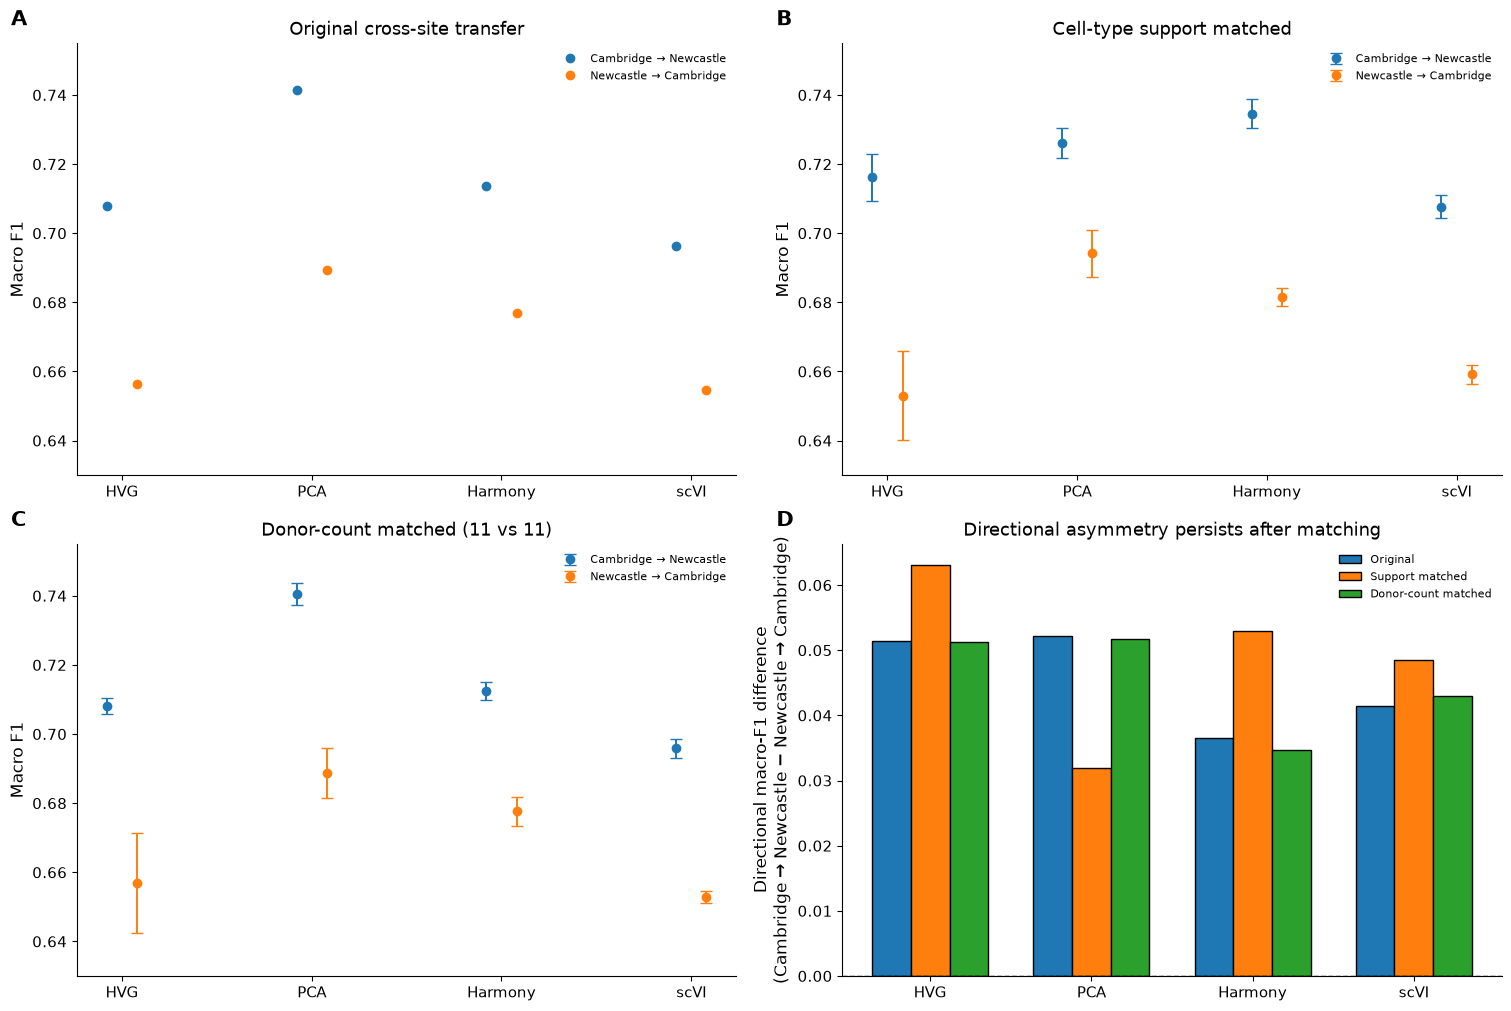

In [5]:
# ============================================================
# Figure S4 — PBMC cross-site transfer diagnostics
# ============================================================

TRANSFER_DIR = (
    REPO_ROOT
    / "results/pbmc_no_batch/group_transfer/Cambridge_vs_Ncl"
)

DIAG_DIR = TRANSFER_DIR / "diagnostics"

original = pd.read_csv(
    TRANSFER_DIR / "group_transfer_summary.csv"
)

support = pd.read_csv(
    DIAG_DIR / "support_matched_transfer_summary.csv"
)

donor_match = pd.read_csv(
    DIAG_DIR / "donor_count_matched_transfer_summary.csv"
)

gap = pd.read_csv(
    DIAG_DIR / "transfer_direction_gap_comparison.csv"
)


fig, axes = plt.subplots(
    2,
    2,
    figsize=(15, 10),
    layout="constrained",
)

rep_order = [
    r for r in REP_ORDER
    if r in set(original["representation"])
]

x = np.arange(len(rep_order))

direction_order = [
    "Cambridge_to_Ncl",
    "Ncl_to_Cambridge",
]

direction_labels = {
    "Cambridge_to_Ncl": "Cambridge → Newcastle",
    "Ncl_to_Cambridge": "Newcastle → Cambridge",
}

offsets = [-0.08, 0.08]

# Use the same y-axis range for A–C
transfer_ylim = (0.63, 0.755)


# ------------------------------------------------------------
# A. Original transfer
# ------------------------------------------------------------

ax = axes[0, 0]

for j, direction in enumerate(direction_order):
    sub = (
        original[original["direction"].eq(direction)]
        .set_index("representation")
        .reindex(rep_order)
    )

    ax.plot(
        x + offsets[j],
        sub["macro_f1"],
        linestyle="None",
        marker="o",
        markersize=6,
        label=direction_labels[direction],
    )

ax.set_xticks(
    x,
    [REP_LABELS[r] for r in rep_order],
)
ax.set_ylabel("Macro F1")
ax.set_ylim(*transfer_ylim)
ax.set_title("Original cross-site transfer")
ax.legend(frameon=False, fontsize=8)

clean_axis(ax)
panel_letter(ax, "A", x=-0.10, y=1.03)


# ------------------------------------------------------------
# B. Cell-type support-matched transfer
# ------------------------------------------------------------

ax = axes[0, 1]

for j, direction in enumerate(direction_order):
    sub = (
        support[support["direction"].eq(direction)]
        .set_index("representation")
        .reindex(rep_order)
    )

    ax.errorbar(
        x + offsets[j],
        sub["macro_f1_mean"],
        yerr=sub["macro_f1_std"],
        fmt="o",
        markersize=6,
        capsize=4,
        linewidth=1.4,
        label=direction_labels[direction],
    )

ax.set_xticks(
    x,
    [REP_LABELS[r] for r in rep_order],
)
ax.set_ylabel("Macro F1")
ax.set_ylim(*transfer_ylim)
ax.set_title("Cell-type support matched")
ax.legend(frameon=False, fontsize=8)

clean_axis(ax)
panel_letter(ax, "B", x=-0.10, y=1.03)


# ------------------------------------------------------------
# C. Donor-count matched transfer
# ------------------------------------------------------------

ax = axes[1, 0]

for j, direction in enumerate(direction_order):
    sub = (
        donor_match[donor_match["direction"].eq(direction)]
        .set_index("representation")
        .reindex(rep_order)
    )

    ax.errorbar(
        x + offsets[j],
        sub["macro_f1_mean"],
        yerr=sub["macro_f1_std"],
        fmt="o",
        markersize=6,
        capsize=4,
        linewidth=1.4,
        label=direction_labels[direction],
    )

ax.set_xticks(
    x,
    [REP_LABELS[r] for r in rep_order],
)
ax.set_ylabel("Macro F1")
ax.set_ylim(*transfer_ylim)
ax.set_title("Donor-count matched (11 vs 11)")
ax.legend(frameon=False, fontsize=8)

clean_axis(ax)
panel_letter(ax, "C", x=-0.10, y=1.03)


# ------------------------------------------------------------
# D. Directional-gap comparison
# ------------------------------------------------------------

ax = axes[1, 1]

analysis_order = [
    "original",
    "support matched",
    "donor-count matched",
]

analysis_labels = {
    "original": "Original",
    "support matched": "Support matched",
    "donor-count matched": "Donor-count matched",
}

width = 0.24

for j, analysis in enumerate(analysis_order):
    sub = (
        gap[gap["analysis"].eq(analysis)]
        .set_index("representation")
        .reindex(rep_order)
    )

    ax.bar(
        x + (j - 1) * width,
        sub[
            "direction_gap_Cambridge_to_Ncl_minus_reverse"
        ],
        width=width,
        label=analysis_labels[analysis],
        edgecolor="black",
    )

ax.axhline(
    0,
    linestyle="--",
    linewidth=1,
    color="black",
)

ax.set_xticks(
    x,
    [REP_LABELS[r] for r in rep_order],
)

ax.set_ylabel(
    "Directional macro-F1 difference\n"
    "(Cambridge → Newcastle − Newcastle → Cambridge)"
)

ax.set_title(
    "Directional asymmetry persists after matching"
)

ax.legend(
    frameon=False,
    fontsize=8,
)

clean_axis(ax)
panel_letter(ax, "D", x=-0.10, y=1.03)

export_figure(fig, "figure_S4_pbmc_transfer")
plt.show()

## Figure S5 — Synthetic-label audits


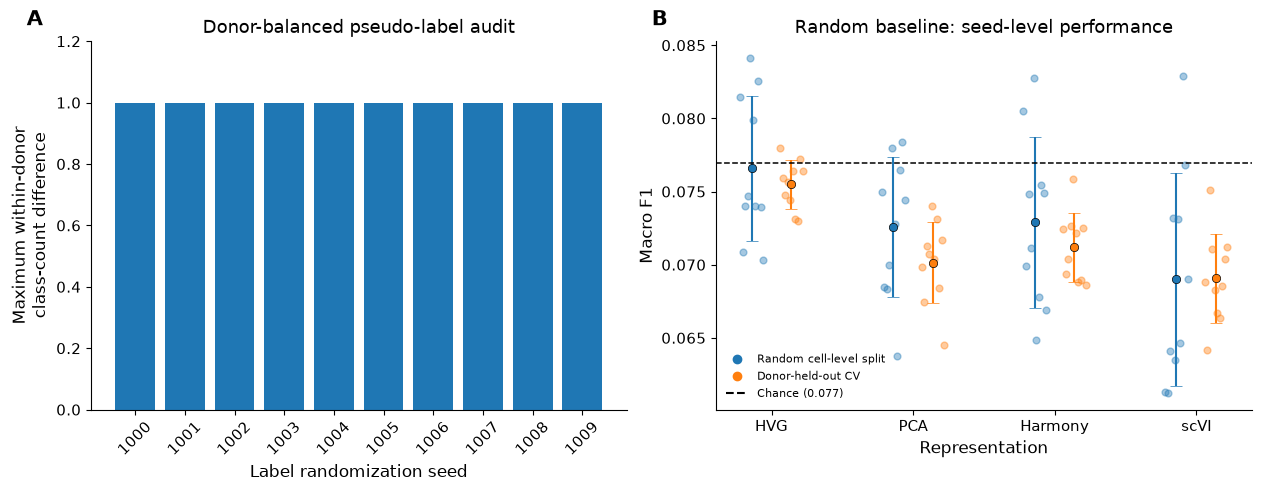

In [6]:
# ============================================================
# Figure S5 — Synthetic floor-control audits
# ============================================================

SYN_DIR = REPO_ROOT / "results/synthetic_floor"

replicates = pd.read_csv(
    SYN_DIR / "null_control_replicates.csv"
)

balance = pd.read_csv(
    SYN_DIR / "null_label_balance.csv"
)

with open(
    SYN_DIR / "config.json",
    "r",
    encoding="utf-8",
) as handle:
    config = json.load(handle)

donor_col = config["donor_col"]
chance = float(config["chance_macro_f1"])


fig, axes = plt.subplots(
    1,
    2,
    figsize=(12.5, 4.8),
    layout="constrained",
)


# ------------------------------------------------------------
# A. Maximum within-donor pseudo-label imbalance by seed
# ------------------------------------------------------------

ax = axes[0]

donor_seed_imbalance = (
    balance
    .groupby(["label_seed", donor_col])["n_cells"]
    .agg(lambda x: x.max() - x.min())
    .reset_index(name="max_minus_min")
)

seed_max = (
    donor_seed_imbalance
    .groupby("label_seed")["max_minus_min"]
    .max()
)

ax.bar(
    seed_max.index.astype(str),
    seed_max.values,
    color=BLUE,
)

ax.set_xlabel("Label randomization seed")
ax.set_ylabel(
    "Maximum within-donor\nclass-count difference"
)
ax.set_title(
    "Donor-balanced pseudo-label audit"
)

ax.tick_params(
    axis="x",
    rotation=45,
)

ax.set_ylim(
    0,
    max(1.2, seed_max.max() + 0.2),
)

clean_axis(ax)
panel_letter(
    ax,
    "A",
    x=-0.12,
    y=1.03,
)


# ------------------------------------------------------------
# B. Seed-level absolute performance stays near chance
# ------------------------------------------------------------

ax = axes[1]

rep_order = [
    r for r in REP_ORDER
    if r in set(replicates["representation"])
]

scheme_specs = [
    (
        "random_split",
        BLUE,
        "Random cell-level split",
    ),
    (
        "donor_cv",
        ORANGE,
        "Donor-held-out CV",
    ),
]

positions = np.arange(len(rep_order))

for s_idx, (scheme, color, label) in enumerate(scheme_specs):

    for i, rep in enumerate(rep_order):

        values = (
            replicates.loc[
                replicates["scheme"].eq(scheme)
                & replicates["representation"].eq(rep),
                "macro_f1_mean",
            ]
            .dropna()
            .to_numpy()
        )

        center = (
            positions[i]
            + (-0.14 if s_idx == 0 else 0.14)
        )

        offsets = np.linspace(
            -0.08,
            0.08,
            len(values),
        )

        ax.scatter(
            center + offsets,
            values,
            color=color,
            alpha=0.40,
            s=24,
        )

        ax.errorbar(
            center,
            values.mean(),
            yerr=values.std(ddof=1),
            fmt="o",
            color=color,
            markeredgecolor="black",
            markeredgewidth=0.5,
            capsize=4,
            markersize=6,
        )


ax.axhline(
    chance,
    color="black",
    linestyle="--",
    linewidth=1.1,
)

ax.set_xticks(
    positions,
    [REP_LABELS[r] for r in rep_order],
)

ax.set_xlabel("Representation")
ax.set_ylabel("Macro F1")
ax.set_title("Random baseline: seed-level performance")

handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="None",
        color=BLUE,
        label="Random cell-level split",
    ),
    Line2D(
        [0], [0],
        marker="o",
        linestyle="None",
        color=ORANGE,
        label="Donor-held-out CV",
    ),
    Line2D(
        [0], [0],
        linestyle="--",
        color="black",
        label=f"Chance ({chance:.3f})",
    ),
]

ax.legend(
    handles=handles,
    frameon=False,
    fontsize=8,
)

clean_axis(ax)
panel_letter(
    ax,
    "B",
    x=-0.12,
    y=1.03,
)


export_figure(fig, "figure_S5_random_baseline_audits")

plt.show()